#### 복습
- LLM = 대규모 언어 모델 (언 어!!)
- 에이전트 = 특정 작업을 수행하는 주체 (모델, 도구, 실행절차를 가진 주체...)
- Tool = 에이전트가 사용하는 도구 (예: 데이터베이스, API, 파일 시스템 등)
- State = 그래프에서 전체적으로 값을 기억하고 기록하는 역할
- Node = 그래프에서 상태를 나타내는 단위(내부적으론 함수로 나타냄)
- Edge = 그래프에서 노드 간의 관계를 나타내는 단위
- 노드와 에이전트의 차이점:
    - 노드: 그래프 안에서 실행단이 1개임
        - 노드는 llm이 들어있을수도 있고 단순한 함수일 수도 있음(안들어있을수도 있다는 말)
    - 에이전트: 목표를 가지고 실행할 수 있는 시스템이고 노드를 포함할 수 있음
        - 에이전트는 무조건 llm을 가지고 있어야 함
        - 즉, 에이전트는 여러 노드를 조합하여 복잡한 작업을 수행할 수 있음

![복습이미지](./images/ref/06_01.png)

___
```Markdown - 서론
이제는 시작이 있으면 llm에게 질문을 던지고 이 llm자체가 '검색이 필요한데?'하고 검색을 할건데
이 검색하는 툴 중에(Tavli...말고도 여러개 많음) 어떤 툴을 사용할지 llm이 판단해서 검색을 수행하게 될 것임

그럼 저 검색툴도 노드로 등록되어야 있어야 했는데
에이전트를 하나 만들어서 검색 엔진을 다 집어넣어두고
하나의 특정 전문 분야들끼리 묶어 에이전트를 만들고?

그 여러 에이전트들을 = 전문가 집단을 만들어 협업하게 할 수 있음!!
```

# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움!
- Multi Agent는 작업을 역할별로 나누고, 각 결과를 다음 담당자에게 전달함~!! (전문가 집단!)
    - [Multi Agent 종류]
    - Network: 동료 간 상호 위임이 가능한 연결 구조(거미줄처럼 연결되어있음)
    - Supervisor: 여러 담당자의 순서를 결정하는 중앙 관리자(나머지 에이전트를 컨트롤하는 심판 역할)
    - Hierarchical: 팀 안에 팀이 있는 계층적인 조직(Supervisor 확장판으로, 여러 계층의 관리자가 존재함)
    - Custom: 특정 요구사항에 맞게 설계된 맞춤형 구조(내가 만들고싶은 상태로 수정해서 만드는~~ | 위 3개가 기본적인거임)


### **1-1. 용어 설명**

#### 1-1-1. HandOff
- 현재 담당자가 다른 담당자에게 실행 제어권을 넘기는 것
- 그래프상에서 에이전트가 서로 다른 경우를 말하는데, 한 에이전트가 수행하던 작업을 다른 에이전트가 이어받아 수행하게 되는 상황을 의미함.

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
# 에이전트 간 공유할 상태
class HandoffState(TypedDict, total=False):
    request: str        # 사용자 요청
    department: str     # 담당 부서
    answer: str         # 답변

# 요청 내용에 따라 담당 부서 결정
def triage(state: HandoffState):
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    return {"department": dept}

# 코딩 담당: 코드 예제 반환
def coding(state: HandoffState):
    return {"answer": f"[코딩 담당] {state['request']} > 예제: for x in [1, 2, 3]: print(x)"}

# 글쓰기 담당: 글 구성 안내 반환
def writing(state: HandoffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

# 결정된 담당 부서로 이동할 경로 반환
def route_handoff(state: HandoffState):
    return state["department"]

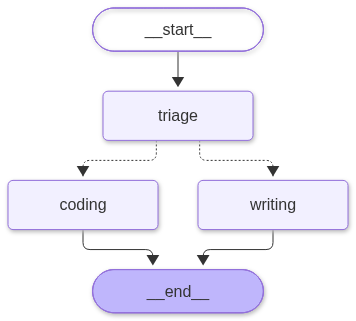

In [3]:
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

builder.add_edge(START, "triage")
builder.add_conditional_edges("triage", route_handoff, {"coding": "coding", "writing": "writing"})
builder.add_edge("coding", END)
builder.add_edge("writing", END)

handoff_graph = builder.compile()
handoff_graph

In [4]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request": q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩 담당] 파이썬 for문 설명해줘 > 예제: for x in [1, 2, 3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [5]:
# stream_mode="updates": 과정이 보임
# 근데 지금은 단일 에이전트고 멀티에이전트로 바꾸려면 아래 코드셀 확인!
for update in handoff_graph.stream({"request": "파이썬 리스트 예제"}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩 담당] 파이썬 리스트 예제 > 예제: for x in [1, 2, 3]: print(x)'}}


In [6]:
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from typing import TypedDict, Literal

In [7]:
llm = ChatOpenAI(model="gpt-5.6-luna", temperature=0)

# ★★ 1. 분류 에이전트(노드 아님!!)
# Command: 실질적으로 Handoff를 실행하는건데 (이게 이제 에이전트들과 주고받기가 가능하게 해주는거임)
# Literal: 특정 값만 허용하도록 타입 지정
def triage(state: HandoffState) -> Command[Literal["coding", "writing"]]:
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    # goto: 이동할 에이전트 지정(명령어임) -> 다음에 실행할 노드 지정과 같은 말
    # update: 공유 상태(State)에 department 정보를 저장함
    return Command(update={"department": dept}, goto=dept)


# ★★ 2. 코딩 에이전트(노드 아님!!)
def coding(state: HandoffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}


# ★★ 3. 글쓰기 에이전트(노드 아님!!)
def writing(state: HandoffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요. \n요청: {state['request']}"
    )
    return {"answer": response.content}

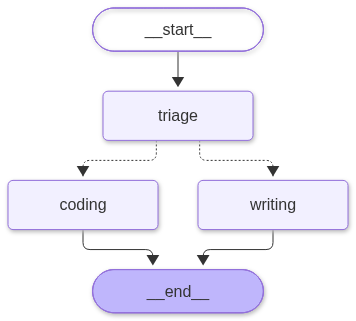

In [8]:
# 이제 위에걸로 그래프 구성!
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

# 멀티 에이전트에선 add_conditional_edges가 필요 없고, triage에서 바로 각 에이전트로 이동함(goto 사용)
builder.add_edge(START, "triage")
builder.add_edge("coding", END)
builder.add_edge("writing", END)

graph = builder.compile()
graph

In [9]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request": q})
    print(f"\n질문: {q}")
    print(f"담당: {result['department']}")
    print(f"답변: {result['answer']}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: # 파이썬 `for`문이란?

`for`문은 **반복해서 작업할 때** 사용하는 문법입니다.

예를 들어 리스트의 모든 값을 하나씩 출력할 때 사용합니다.

## 기본 문법

```python
for 변수 in 반복할_자료:
    실행할_문장
```

예시:

```python
fruits = ["사과", "바나나", "포도"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
포도
```

`for`문은 리스트에서 값을 하나씩 꺼내 `fruit` 변수에 저장한 뒤, `print(fruit)`를 반복 실행합니다.

---

## 1. 숫자를 반복할 때: `range()`

```python
for i in range(5):
    print(i)
```

결과:

```text
0
1
2
3
4
```

`range(5)`는 **0부터 4까지**의 숫자를 만듭니다.

### 시작과 끝 지정

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

`range(1, 6)`은 1부터 시작해서 **6 전까지** 반복합니다.

### 증가 간격 지정

```python
for i in range(0, 10, 2):
    print(i)
```

결과:

```text
0
2
4
6
8
```

형식은 다음과 같습니다.

```python
range(시작값, 끝값, 증가값)
```

---

## 2. 문자열도 반복할 수 있습니다

문자열의 글자를 하나씩 확인할 수 있습니다.

```python
word = "Python"

for letter in word:
    print(letter)
```

결과:

```text
P
y
t
h
o
n
```

---

## 3. 반복하면서 계산하기

```python
total = 0

for number in

![에이전트와 멀티에이전트 차이](./images/ref/06_02.png)

### **1-2. 종류1) Network**
각 전문 에이전트로 되어 있으며 직접 이웃 에이전트로 handoff를 한다.

In [10]:
from tavily import TavilyClient
from dotenv import load_dotenv
from pathlib import Path
from pydantic import BaseModel, Field  # llm이 값을 줄 때 구조화시켜 줄 수 있도록 하는..
import os, json
import matplotlib.pyplot as plt

In [11]:
load_dotenv()

True

In [12]:
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError(".env 파일에 OPENAI API KEY가 설정되어 있지 않습니다.")

llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5.6-luna"), temperature=0)

In [13]:
OUTPUT_DIR = Path("multi_agent_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

[에이전트를 네트워크형식으로 구현해볼게~]

In [14]:
# llm에게 지시와 사용자 입력을 구분해서 질문 보냄
def ask(system: str, user: str) -> str:
    """시스템 지시와 사용자 입력을 구분해 LLM을 호출합니다."""
    response = llm.invoke([("system", system), ("human", user)])
    return str(response.content)

In [15]:
# 차트 상태
class ChartState(TypedDict, total=False):
    question: str
    sources: list[dict]
    data: list[dict]
    summary: str
    chart_path: str
    error: str

# 차트 데이터
class ChartData(TypedDict):
    label: str
    value: float

In [16]:
# 웹 검색 함수
def search_web(query: str) -> list[dict]:
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError(".env 파일에 TAVILY API KEY가 설정되어 있지 않습니다.")
    result = TavilyClient(api_key=key).search(query=query, max_results=5)
    return [{
        "title": x.get("title", ""), 
        "url": x.get("url", ""), 
        "content": x.get("content", "")[:1500]
    } for x in result.get("results", [])]

In [17]:
# llm이 주는 값을 구조화시킴
class ResearchData(BaseModel):
    data: list[ChartData] = Field(description="출처에서 확인된 수치만 포함!")
    summary: str

In [18]:
# 구조화된 출력이 가능한 llm 생성함
research_llm = llm.with_structured_output(ResearchData)

In [19]:
# 연구자 역할을 수행해서 검색결과 분석하고, 검증 가능한 수치 추출함
def resercher(state: ChartState) -> Command[Literal["chart", "__end__"]]:
    # 사용자 질문 기반으로 웹 검색 수행
    sources = search_web(state["question"])
    # 검색 결과에서 검증 가능한 수치를 추출
    parsed = research_llm.invoke([
        ("system", "검색 결과에 명시된 값만 추출하세요. 추정하거나 없는 수치를 생성하지 마세요. 각 수치의 단위가 일관되어야 합니다. 확인 불가능하면 data를 빈 목록으로 반환하세요."),
        ("human", json.dumps({"question": state["question"], "sources": sources}, ensure_ascii=False))
    ])

    # parsed 데이터가 없으면 에러 저장 후 종료
    if not parsed.data:
        return Command(update={
            "sources": sources,
            "error": "검증 가능한 수치가 없습니다."
        }, goto=END)
    # 그게 아니라면(데이터가 있다면)
    # 검색 결과, 수치, 요약을 저장하고 차트노드로 이동
    return Command(update={
        "sources": sources,
        "data": [x.model_dump() if hasattr(x, "model_dump") else x for x in parsed.data],
        "summary": parsed.summary
    }, goto="chart")

In [20]:
def chart(state: ChartState) -> Command[Literal["__end__"]]:
    rows = state["data"]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar([r["label"] for r in rows], [r["value"] for r in rows])
    ax.set_title("Research results (verify units and sources)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    path = OUTPUT_DIR / "research_chart.png"
    fig.savefig(path, dpi=140)
    plt.show()
    plt.close(fig)
    return Command(update={"chart_path":str(path)}, goto=END)

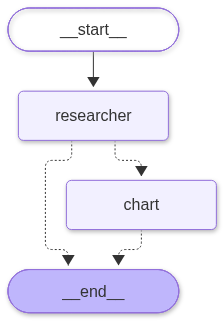

In [21]:
builder = StateGraph(ChartState)

builder.add_node("researcher", resercher)
builder.add_node("chart", chart)
# END를 쓸 필요가 없음
# why?! 
# 위에서 Command(goto=END)를 사용했으니까 여기서 END 정의 안해도됨 쩐다!!

builder.add_edge(START, "researcher")
network_chart = builder.compile()
network_chart

In [22]:
# 맷플로립 한글깨짐 방지
import matplotlib as mpl

# 한글 폰트 설정 (Windows)
mpl.rcParams["font.family"] = "Malgun Gothic"
# 마이너스(-) 기호 깨짐 방지
mpl.rcParams["axes.unicode_minus"] = False

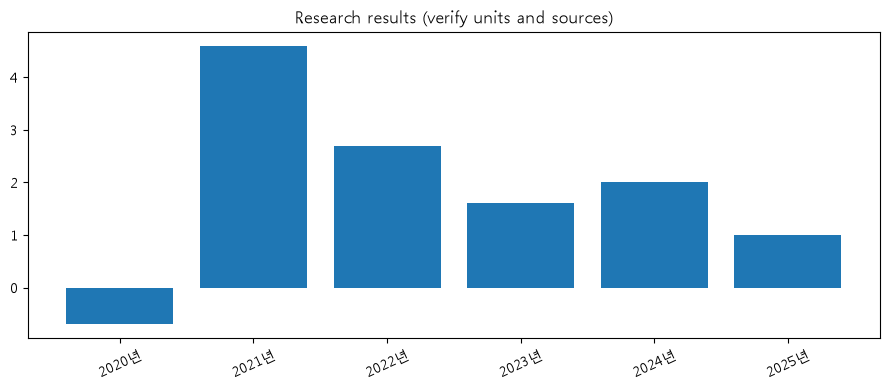

In [23]:
result = network_chart.invoke(
    {"question": "2020년부터 2025년까지 한국의 연도별 실질 GDP 성장률(%)"}, 
    config={"recursion_limit": 5}
)

#### 2-1-1. 실습) 멀티 에이전트 기반(Network) AI 맞춤형 학습 진단 및 문제 출제 시스템
학생의 과목별 학습 점수를 분석해 가장 취약한 학습 영역을 찾아내고, 해당 영역에 대한 맞춤형 문제를 자동으로 출제하는 AI 학습 진단 멀티 에이전트 시스템 개발해보기

- Diagnosis Agent: 학생의 영역별 점수를 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성
- Quiz Agent: 진단 결과를 받아 취약 영역에 대한 객관식 문제 생상

```
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}

1. 학생의 학습 점수를 입력받음
2. 모든 점수가 0~100점 사이인지 검사
3. 가장 점수가 낮은 학습 영역을 찾음
4. llm을 이용해 학생의 학습 상태를 3문장으로 진단
5. 진단 결과를 문제 출제 에이전트에게 전달
6. llm을 이용해 취약 영역에 대한 객관식 문제 3개를 생성
7. 각 문제에 정답과 해설을 포함
8. 최종 진단 결과와 생성된 문제를 출력
```

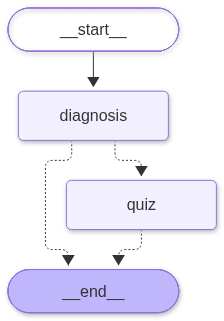

In [24]:
# 에이전트들이 공유할거
class StudyStatemy(TypedDict, total=False):
    scores: dict[str, int]
    down_subject: str
    diagnosis: str
    quiz_ss: list[dict]
    error: str


# 첫번째 에이전트: Diagnosis Agent
def diagnosismy(state: StudyStatemy) -> Command[Literal["quiz", "__end__"]]:
    # 1단계) 과목별 점수 가져옴
    scores = state["scores"]
    # 2단계) 점수 검사(0~100점)
    if not scores or any(
        type(score) not in (int, float) or not 0 <= score <= 100
        for score in scores.values()
    ):
        return Command(
            update={"error": "점수는 0~100 사이여야 합니다."}, goto=END
        )
    # 3단계) 가장 점수 낮은애
    down_subject = min(scores, key=scores.get)
    # 4단계) llm 이용해서 3문장 진단하기
    response = llm.invoke([
        ("system", "학습 진단 전문가가 되어 학생의 과목별 점수를 분석하고 학습 상태를 3문장으로 진단하세요."),
        ("human", f"과목별 점수: {scores} | 취약 과목: {down_subject}")
    ])
    # 5단계) 결과 문제 출제 에이전트에 전달하기
    return Command(
        update={
            "down_subject": down_subject,
            "diagnosis": str(response.content)
        }, goto="quiz"
    )

# 객관식 문제 하나의 구조 정의 -> 이것도 해야지!!
class QuizDatamy(TypedDict):
    question: str
    options: list[str]
    answer: int
    explanation: str

# llm이 주는 값 구조화 시키기
class ResearchQuizmy(BaseModel):
    # quiz_ss: list[dict[str, str]] 이걸 이렇게 쓰면 안돼고..아래처럼 써야지!!
    quiz_ss: list[QuizDatamy] = Field(
        description="취약 과목에 대한 객관식 4지선다 문제 3개와 각 문제의 정답 번호, 해설"
    )

# llm 생성
quiz_llm = llm.with_structured_output(ResearchQuizmy)

# 두번째 에이전트 Quiz Agent
def quiz(state: StudyStatemy) -> Command[Literal["__end__"]]:
    # 첫번째 에이전트가 전달한 결과 받아옴
    down_subject = state["down_subject"]
    diagnosis = state["diagnosis"]
    # 6단계 + 7단계) llm 이용해서 문제 만듦
    parsed = quiz_llm.invoke([
        ("system", "학습 문제 출제 전문가가 되어 학생의 취약 과목과 학습 진단 결과를 합고해 객관식 4지선다 문제를 3개 생성하세요. 문제는 정답과 해설을 포함하세요."),
        ("human", f"취약 과목: {down_subject} | 진단: {diagnosis}")
    ])
    # 문제 출제 끝. 그래프 종료
    return Command(
        update={"quiz_ss": parsed.quiz_ss}, goto=END
    )


# 이제 그래프 그려
mybuilder = StateGraph(StudyStatemy)

mybuilder.add_node("diagnosis", diagnosismy)
mybuilder.add_node("quiz", quiz)

mybuilder.add_edge(START, "diagnosis")

my_graph = mybuilder.compile()
my_graph

In [25]:
# 이제 실행해보자
scores = {
    "파이썬 기초문법": 90,
    "데이터 분석": 75,
    "딥러닝": 60
}

result = my_graph.invoke({"scores": scores})
result

{'scores': {'파이썬 기초문법': 90, '데이터 분석': 75, '딥러닝': 60},
 'down_subject': '딥러닝',
 'diagnosis': '파이썬 기초문법은 90점으로 기초 프로그래밍 역량이 매우 탄탄합니다.  \n데이터 분석은 75점으로 기본 개념은 이해하고 있으나 실습과 문제 적용 능력을 보완할 필요가 있습니다.  \n딥러닝은 60점으로 가장 취약하므로 선형대수·확률 기초를 복습한 뒤, 신경망 구조와 학습 과정을 작은 실습부터 단계적으로 학습하는 것이 좋습니다.',
 'quiz_ss': [{'question': '입력 벡터 x와 가중치 벡터 w의 내적을 이용해 뉴런의 선형 결합을 계산할 때, 올바른 식은 무엇인가?',
   'options': ['z = x + w + b',
    'z = wᵀx + b',
    'z = wᵀ + x + b',
    'z = xᵀx + wᵀw'],
   'answer': 2,
   'explanation': '뉴런은 입력 x와 가중치 w의 내적에 편향 b를 더해 선형 결합 z = wᵀx + b를 계산합니다. 이후 이 값에 활성화 함수를 적용해 출력값을 만듭니다.'},
  {'question': '이진 분류 문제에서 출력층의 활성화 함수로 시그모이드 함수를 사용하고, 정답이 1일 때 예측값이 0.9에서 0.6으로 변했다면 일반적으로 어떤 변화가 발생하는가?',
   'options': ['이진 교차 엔트로피 손실이 감소한다.',
    '이진 교차 엔트로피 손실이 증가한다.',
    '가중치와 무관하게 손실은 항상 0이다.',
    '정답이 1이므로 손실은 음수가 된다.'],
   'answer': 2,
   'explanation': '정답이 1인 경우 예측값이 1에 가까울수록 이진 교차 엔트로피 손실이 작습니다. 예측값이 0.9에서 0.6으로 멀어지면 손실은 증가합니다. 손실은 일반적으로 음수가 아닙니다.'},
  {'question': '신경망 학습에서 경사하강법을 사용할 때, 학습률을

In [26]:
# 검증도 - GPT도움
if result.get("error"):
    print("오류:", result["error"])

else:
    print("===== 학습 진단 =====")
    print("취약 과목:", result["down_subject"])
    print("진단:", result["diagnosis"])

    print("\n===== 객관식 문제 =====")

    for i, q in enumerate(result["quiz_ss"], start=1):
        print(f"\n문제 {i}. {q['question']}")

        for j, option in enumerate(q["options"], start=1):
            print(f"{j}. {option}")

        print(f"정답: {q['answer']}번")
        print(f"해설: {q['explanation']}")

===== 학습 진단 =====
취약 과목: 딥러닝
진단: 파이썬 기초문법은 90점으로 기초 프로그래밍 역량이 매우 탄탄합니다.  
데이터 분석은 75점으로 기본 개념은 이해하고 있으나 실습과 문제 적용 능력을 보완할 필요가 있습니다.  
딥러닝은 60점으로 가장 취약하므로 선형대수·확률 기초를 복습한 뒤, 신경망 구조와 학습 과정을 작은 실습부터 단계적으로 학습하는 것이 좋습니다.

===== 객관식 문제 =====

문제 1. 입력 벡터 x와 가중치 벡터 w의 내적을 이용해 뉴런의 선형 결합을 계산할 때, 올바른 식은 무엇인가?
1. z = x + w + b
2. z = wᵀx + b
3. z = wᵀ + x + b
4. z = xᵀx + wᵀw
정답: 2번
해설: 뉴런은 입력 x와 가중치 w의 내적에 편향 b를 더해 선형 결합 z = wᵀx + b를 계산합니다. 이후 이 값에 활성화 함수를 적용해 출력값을 만듭니다.

문제 2. 이진 분류 문제에서 출력층의 활성화 함수로 시그모이드 함수를 사용하고, 정답이 1일 때 예측값이 0.9에서 0.6으로 변했다면 일반적으로 어떤 변화가 발생하는가?
1. 이진 교차 엔트로피 손실이 감소한다.
2. 이진 교차 엔트로피 손실이 증가한다.
3. 가중치와 무관하게 손실은 항상 0이다.
4. 정답이 1이므로 손실은 음수가 된다.
정답: 2번
해설: 정답이 1인 경우 예측값이 1에 가까울수록 이진 교차 엔트로피 손실이 작습니다. 예측값이 0.9에서 0.6으로 멀어지면 손실은 증가합니다. 손실은 일반적으로 음수가 아닙니다.

문제 3. 신경망 학습에서 경사하강법을 사용할 때, 학습률을 지나치게 크게 설정하면 발생할 가능성이 가장 높은 현상은 무엇인가?
1. 손실이 안정적으로 감소하며 매우 빠르게 수렴한다.
2. 가중치가 전혀 변경되지 않는다.
3. 최솟값을 지나치거나 손실이 발산하여 학습이 불안정해진다.
4. 활성화 함수가 자동으로 제거된다.
정답: 3번
해설: 경사하강법의 가중치 갱신은 일반적으로 w ← w - η∇L 형태입니

이 아래가 강사님 코드!!

In [27]:
class StudyState(TypedDict, total=False):
    scores: dict[str, int]
    weakness: str
    diagnosis: str
    quiz: str

def diagnosis(state: StudyState) -> Command[Literal["quiz"]]:
    scores = state["scores"]
    if not scores or any(not 0 <= v <= 100 for v in scores.values()):
        raise ValueError("영역별 점수를 0~100 사이로 입력하세요")
    weak = min(scores, key=scores.get)
    explanation = ask(
        "당신은 친절한 학습 진단 전문가입니다. 점수의 의미를 과장하지 말고 3문장으로 분석하세요", 
        f"영역별 점수: {scores}, 취약 과목: {weak}"
    )
    return Command(update={"weakness": weak, "diagnosis": explanation}, goto="quiz")

def quiz(state: StudyState) -> Command[Literal["__end__"]]:
    content = ask(
        "당신은 학습문제 출제 전문가입니다. 지정된 취약 과목에 대해 객관식 3문제를 만들고 각 문항에 정답과 쉬운 해설을 붙이세요. 애매한 문항은 피하세요.",
        f"취약 과목: {state['weakness']} | 진단: {state['diagnosis']}"
    )
    return Command(update={"quiz": content}, goto=END)

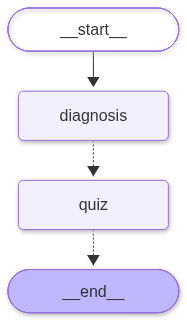

In [28]:
builder = StateGraph(StudyState)
builder.add_node("diagnosis", diagnosis)
builder.add_node("quiz", quiz)
builder.add_edge(START, "diagnosis")
study_network = builder.compile()
study_network

In [29]:
result = study_network.invoke(
    {"scores": {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}},
    config={"recursion_limit": 5}
)

In [30]:
print("[진단]", result["diagnosis"], "\n[문제]", result["quiz"])

[진단] 파이썬 기초문법은 90점으로 기본기가 비교적 탄탄한 편입니다.  
데이터 분석은 75점으로 핵심 개념은 갖추었지만 실습과 문제 적용을 통해 보완할 여지가 있습니다.  
딥러닝은 60점으로 상대적으로 취약하므로, 신경망 기초·손실 함수·역전파 개념을 중심으로 작은 예제를 직접 구현하며 학습하는 것이 좋습니다. 
[문제] ## 딥러닝 기초 객관식 문제

### 1번. 신경망의 순전파 계산

다음 뉴런의 출력값을 계산하세요. 활성화 함수는 ReLU입니다.

- 입력: \(x_1=2,\ x_2=1\)
- 가중치: \(w_1=0.5,\ w_2=-1\)
- 편향: \(b=1\)
- ReLU 함수: \(\text{ReLU}(z)=\max(0,z)\)

① 0  
② 0.5  
③ 1  
④ 2  

**정답: ③ 1**

**해설:**  
먼저 가중합을 계산합니다.

\[
z=x_1w_1+x_2w_2+b
\]

\[
z=2(0.5)+1(-1)+1=1
\]

ReLU에 1을 넣으면 그대로 1이므로 출력값은 **1**입니다.

---

### 2번. 손실 함수 계산

예측값이 \(0.8\), 실제값이 \(1\)일 때, 다음 평균제곱오차 형태의 손실값을 계산하세요.

\[
L=\frac{1}{2}(\hat{y}-y)^2
\]

① 0.02  
② 0.04  
③ 0.2  
④ 0.8  

**정답: ① 0.02**

**해설:**  

\[
L=\frac{1}{2}(0.8-1)^2
\]

\[
=\frac{1}{2}(-0.2)^2
=\frac{1}{2}\times 0.04
=0.02
\]

따라서 손실값은 **0.02**입니다. 손실값은 예측값과 실제값의 차이가 작을수록 작아집니다.

---

### 3번. 역전파와 가중치 업데이트

활성화 함수가 없는 단일 뉴런에서 다음과 같이 정의되어 있습니다.

\[
\hat{y}=wx,\qquad L=\frac{1}{2}(\hat{y}-y)^2
\]

현재 값이 다음과 같을 때, 학습률이 \(0.1\)이면 경사하강법으로 업데이트

### **1-3. 종류2) Supervisor**
Supervisor가 여러 전문 에이전트에게 작업을 순서대로 맡기고, 모든 작업이 끝나면 결과를 반환하는 구조

In [36]:
# total=False : 이 안에 있는 모든 데이터가 다 채워질 필요 없다는 뜻
class TripState(TypedDict, total=False):
    request: str             # 사용자의 여행 요청
    sources: list[dict]      # 웹 검색 결과
    research: str            # 조사 에이전트가 작성한 요약
    recommendation: str      # 추천 에이전트가 작성한 결과
    saved_path: str          # 저장된 파일 경로
    next_step: str           # LLM이 선택한 다음 작업
    error: str               # 오류 정보를 기록하기 위한 필드

class RouterDecision(BaseModel):
    next_step: Literal["search_agent", "recommendation_agent", "save_agent", "FINISH"]

In [37]:
router_llm = llm.with_structured_output(RouterDecision)

#### 아래 코드 설명 가지뻗기
- next함수란? 조건함수로 True가 되는 첫 번째 값을 반환하는 함수
- iter함수란? 반복 가능한 객체를 반환하는 함수, 여기선 dict_items를 반복 가능하게 만들어줌
- 그럼 이터러블과 이터레이터의 차이는?
- 이터러블은 반복 가능한 객체이고, 이터레이터는 실제로 반복을 수행하는 객체

```
이터로 감싸면 이러터블이 이터레이터로 변환!
그럼 이게 데이터 순서를 가지니까 반복할 때 순서대로 값을 가져올 수 있는거임
```

In [38]:
# 여행 상태 확인하고 다음에 수행할 에이전트 결정
def supervisor(state: TripState) -> Command[Literal["search_agent", "recommend_agent", "save_agent", "__end__"]]:
    completed = {
        "search_agent": bool(state.get("research")),
        "recommend_agent": bool(state.get("recommendation")),
        "save_agent": bool(state.get("saved_path"))
    }

    # all: 모두 다 참일때만 다음 단계로 진행(지금 코드에선 END로 보내게 됨)
    if all(completed.values()):
        return Command(goto=END)

    # 여행 감독자에게 다음 수행할 작업을 결정하도록 요청
    decision = router_llm.invoke([
        ("system", "당신은 여행 작업 감독자입니다. 반드시 검색, 추천, 저장 순서로 진행하세요. 이미 완료한 작업은 반복하지 마세요. 다음 작업 이름만 선택하세요."),
        ("human", json.dumps({"request": state["request"], "completed": completed}, ensure_ascii=False))
    ])

    # 다음 수행할 작업을 결정한 후, 아직 완료되지 않은 첫 번째 작업을 expected로 설정
    expected = next(k for k, v in completed.items() if not v)

    return Command(update={"next_step": decision.next_step}, goto=expected)

In [ ]:
# 여행 조사원 에이전트
def trip_search(state: TripState) -> Command[Literal["supervisor"]]:
    sources = search_web(state["request"] + "여행 추천 관광지 날씨 예보")
    text = ask("여행 조사원입니다. 출처에 근거한 내용만 요약하고 날짜가 확인되지 않은 날씨는 확정하지 마세요.", json.dumps(sources, ensure_ascii=False))
    return Command(update={"sources": sources, "research": text}, goto="supervisor")

# 추천 전문가 에이전트
def trip_recommend(state: TripState) -> Command[Literal["supervisor"]]:
    text = ask("여행 추천 전문가입니다. 조사 내용을 바탕으로 여행지 3곳과 이유, 날씨 확인 주의사항을 작성하세요. 검증되지 않은 운영시간, 예보는 쓰지 마세요.", state["request"]+"\n"+state["research"])
    return Command(update={"recommendation": text}, goto="supervisor")